# Klasifikasi Kenaikan Harga Produsen Padi Bulan Berikutnya di 16 Negara Asia Periode 2022–2024

Kelompok **17 — Sop Pak Min Klaten**, kelas **IF-B**, UPN “Veteran” Yogyakarta.

| Nama | NIM | Kelas | Kontribusi bersama |
|---|---|---|---|
| Ghazian Muhammad Al Faruq | 123240013 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |
| M. Affan Musyafa' | 123240155 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |
| Firraz Muhammad Raihan Daffa | 123240170 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |
| Jauza Ilham Mahardhika Putra | 123240174 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |

**Cakupan saat ini: Business Understanding dan Data Understanding.** Bagian pertama menjelaskan masalah dan rancangan penelitian. Bagian kedua memuat sumber data, kamus data, pemeriksaan kualitas, EDA, serta audit awal fitur dan pembagian waktu. Seluruh anggota mengerjakan tahap ini bersama dengan kontribusi setara.

Notebook dijalankan menggunakan **Python 3.13.12**. Pilih kernel dengan versi tersebut, lalu jalankan seluruh sel dari awal. Tabel dan grafik berasal dari CSV asli yang disertakan dalam repo. Pelatihan model dan evaluasi kinerjanya masih menjadi tahap berikutnya.


# Business Understanding

## 1. Judul dan tujuan penelitian

Penelitian ini mengkaji apakah riwayat harga dapat membantu mengenali kenaikan harga nominal produsen padi **satu bulan ke depan**. Metode yang dipilih adalah **klasifikasi biner**. Kelas 1 berarti harga naik, sedangkan kelas 0 berarti harga turun atau tetap. Penelitian belum bertujuan memperkirakan nilai harga atau besarnya persentase kenaikan.

Satu contoh analisis mewakili **satu negara pada bulan acuan t**. Cakupan penelitian adalah 16 negara Asia yang memiliki observasi terpilih dalam snapshot FAOSTAT pada 2022–2024. Hasilnya tidak mewakili seluruh Asia.

Komoditas mengikuti label sumber `Rice`, dengan `Item Code=27`. Harga yang digunakan adalah `Producer Price (LCU/tonne)`, yaitu harga produsen dalam mata uang lokal per ton. Istilah padi digunakan sesuai cakupan tersebut. Perbedaan bentuk dan mutu komoditas yang dilaporkan antarnegara tetap menjadi keterbatasan.


## 2. Masalah dan calon pengguna

Koperasi petani padi dan analis kebijakan harga pangan berpotensi membutuhkan ringkasan arah perubahan harga pada tingkat produsen. Namun, manfaat pola harga historis dibandingkan tebakan sederhana belum diketahui.

**Pertanyaan utama:** apakah informasi harga sampai bulan t dapat membantu mengklasifikasikan kenaikan harga pada bulan t+1?

Pertanyaan ini akan dijawab dengan membandingkan model dengan baseline, memeriksa negara yang kurang terwakili, serta membahas risiko alarm palsu dan kenaikan yang terlewat.

Stakeholder tersebut merupakan calon pengguna analisis. Belum ada wawancara atau validasi kebutuhan dari mereka. FAO berperan sebagai penerbit data dan bukan sebagai mitra atau pemberi persetujuan proyek.


## 3. Tujuan SMART

1. **Pada 26 Oktober 2026**, menyelesaikan Business Understanding dan Data Understanding yang dapat diperiksa ulang. Ukurannya adalah tersedianya masalah, stakeholder, tujuan, metrik, asumsi, risiko, sumber dan kamus data, audit kualitas, serta EDA dengan penjelasan.
2. **Pada 30 Oktober 2026**, menyiapkan tahapan awal sesuai panduan, dari pengumpulan data sampai cleaning dan preprocessing, termasuk alasan pembuatan serta pemilihan sedikitnya empat fitur. Versi ini sudah menyediakan audit kalender, fitur, dan pembagian waktu. Pemilihan transformasi untuk model akan dilanjutkan berdasarkan data latih.
3. **Sebelum 22 November 2026**, membandingkan model klasifikasi dari materi praktikum dengan dua baseline pada pembagian waktu yang tetap. Hasil yang dilaporkan mencakup macro-F1, balanced accuracy, recall dan precision kenaikan, serta keterbatasan per negara.

Keberhasilan pengerjaan dinilai dari alur yang dapat dijalankan ulang dan evaluasi yang benar. Peningkatan kinerja terhadap baseline masih harus diuji. Hasil tanpa peningkatan tetap perlu dilaporkan.


## 4. Metode, target, dan baseline

Harga negara c pada bulan t ditulis sebagai P(c,t). Target ditentukan dari **bulan kalender berikutnya pada negara yang sama**:

- `target=1` jika P(c,t+1) > P(c,t).
- `target=0` jika P(c,t+1) ≤ P(c,t), termasuk harga tetap.
- Target tidak tersedia jika salah satu harga tidak tercatat.

Input hanya boleh menggunakan informasi sampai bulan t. Negara dan tanggal berfungsi sebagai identitas panel. Keduanya tidak dihitung sebagai empat fitur harga yang berbeda.

Dua baseline yang akan digunakan adalah **kelas mayoritas pada data latih** dan **persistensi arah**, yaitu memprediksi naik jika perubahan harga satu bulan terakhir positif. Model pembanding akan dipilih dari materi yang telah diajarkan. Belum ada model yang dilatih dalam notebook ini.


## 5. Ukuran keberhasilan

| Metrik | Alasan penggunaan |
|---|---|
| Macro-F1, metrik utama | Memberikan bobot yang sama pada kelas naik dan tidak naik. |
| Balanced accuracy | Merata-ratakan recall kedua kelas ketika komposisinya berbeda. |
| Recall kenaikan | Menunjukkan bagian kenaikan aktual yang berhasil dikenali. |
| Precision kenaikan | Menunjukkan bagian sinyal kenaikan yang benar, sehingga alarm palsu dapat dinilai. |
| Confusion matrix dan accuracy | Memperlihatkan jenis kesalahan dan ringkasan ketepatan sebagai pelengkap. |

Baseline dan model harus dinilai pada observasi yang sama. Hasil akan disajikan secara keseluruhan dan per negara dengan jumlah contohnya. Manfaat prediktif awal didukung jika macro-F1 model lebih tinggi daripada masing-masing baseline, sehingga selisihnya harus lebih dari nol. Ambang manfaat operasional belum divalidasi oleh stakeholder. Macro-F1 bukan persentase prediksi yang benar dan bukan probabilitas harga akan naik.


## 6. Asumsi dan batasan

1. Data berisi harga agregat nasional pada 16 negara terpilih. Data ini tidak menggantikan harga yang diterima setiap petani atau koperasi setempat.
2. Satuan `LCU/tonne` berbeda mata uang antarnegara. Level harganya tidak dibandingkan secara langsung. Perubahan relatif tetap dapat dipengaruhi inflasi atau perubahan rezim mata uang.
3. CSV memuat bulan referensi, tetapi tidak memuat tanggal publikasi dan riwayat revisi. Evaluasi nantinya bersifat retrospektif dan bergantung pada ketersediaan harga bulan t.
4. Bulan yang tidak tercatat tidak diisi dengan nol. Kalender harus dilengkapi sebelum menghitung lag dan rolling agar dua observasi yang berjarak jauh tidak dianggap berurutan.
5. Pembagian data mengikuti tanggal global. Transformasi dan pemilihan fitur dipelajari dari data latih, sedangkan parameter dipilih melalui data validasi.
6. Negara yang muncul pada validasi atau uji dapat tidak hadir pada data latih. Cakupan dan jumlah contoh tiap negara perlu dilaporkan.
7. Data tidak memuat biaya simpan, biaya produksi, stok, cuaca, atau mutu gabah individu. Penelitian ini tidak menjelaskan sebab-akibat dan tidak menjadi dasar langsung untuk menyarankan penundaan penjualan.


## 7. Risiko, etika, dan mitigasi

| Risiko | Dampak | Mitigasi |
|---|---|---|
| Cakupan negara dan tahun tidak merata | Negara dengan data lengkap lebih dominan. | Tampilkan cakupan tiap negara dan batasi generalisasi. |
| Kebocoran informasi masa depan | Evaluasi terlihat terlalu baik. | Gunakan kalender bulanan, fitur sampai t, target t+1, dan pembagian waktu dengan pemeriksaan batas target. |
| Salah membaca harga | Harga produsen dianggap harga konsumen atau harga riil. | Jelaskan definisi farm gate, satuan, dan sifat nominal harga. |
| Alarm palsu atau kenaikan terlewat | Ringkasan arah dapat menyesatkan calon pengguna. | Laporkan precision, recall, confusion matrix, dan batas penggunaan. |
| Atribusi atau penggunaan data tidak sesuai | Hak penerbit tidak dijelaskan atau muncul kesan dukungan FAO. | Cantumkan FAO, snapshot, tautan, lisensi, dan ketentuan tambahannya. |
| Jeda publikasi dan revisi tidak diketahui | Backtest belum tentu sesuai penggunaan langsung. | Jelaskan sifat retrospektif dan periksa ketersediaan data sebelum penerapan nyata. |

Data penelitian berupa harga agregat publik. Nama dan NIM hanya menjadi identitas penyusun. Tidak digunakan data pribadi petani, data sintetis, atau harga tambahan yang dikarang.


## 8. Nilai penggunaan

Hasil penelitian diharapkan menjadi bahan kajian pemantauan arah harga bagi koperasi dan analis kebijakan. Manfaat yang diuji adalah tambahan informasi dibandingkan aturan sederhana. Belum ada bukti keuntungan finansial dari model.

Demo tahap akhir direncanakan memuat `negara`, `bulan_acuan`, `arah_prediksi`, dan `label_aktual` jika tersedia. Skor probabilitas hanya akan ditampilkan jika sifat dan keterbatasannya sudah dijelaskan.

Keputusan memakai model perlu mempertimbangkan kinerja, variasi antarnegara, kebutuhan pemeliharaan data, dan konsekuensi kesalahan. Perhitungan laba belum dapat dilakukan karena data biaya tidak tersedia.


## 9. Pemetaan stakeholder dan data

| Stakeholder | Kebutuhan | Data yang relevan | Batas penggunaan |
|---|---|---|---|
| Koperasi petani padi, calon pengguna | Ringkasan arah harga produsen | Negara, bulan, riwayat harga, dan arah bulan berikutnya | Harga nasional tidak menggantikan harga lokal dan biaya simpan. |
| Analis kebijakan harga pangan, calon pengguna | Perbandingan pola dan cakupan antarnegara | Kode M49, tanggal, perubahan relatif, dan flag sumber | Tidak mendukung klaim sebab-akibat atau representasi seluruh Asia. |
| Kelompok peneliti | Analisis yang dapat dijalankan ulang | CSV asli, checksum, definisi fitur, dan protokol waktu | Setiap proses perlu dipahami dan rencana harus dibedakan dari hasil. |
| FAO, penerbit data | Atribusi dan interpretasi yang tepat | Metadata komoditas, satuan, flag, dan lisensi | Bukan sponsor atau validator hasil penelitian. |


# Data Understanding

## 10.1 Sumber data, cakupan, dan lisensi

Data berasal dari **FAO, FAOSTAT Producer Prices**. Berkas asli pengguna adalah `Agricultural producer prices (Global, National - Annual, Monthly) - FAOSTAT.csv`. Salinannya disimpan sebagai `data/raw/faostat_rice_producer_prices.csv` tanpa mengubah isi. Snapshot diperoleh pada 15 Oktober 2026 menurut catatan proyek dan diverifikasi ulang pada 26 Oktober 2026.

[FAO menjelaskan](https://www.fao.org/prices/en) harga produsen sebagai harga pada tingkat farm gate atau penjualan pertama. Harga ini berbeda dari harga eceran, harga ekspor, dan indeks harga beras internasional. Satuan yang dipilih adalah mata uang lokal per ton.

Penelitian menggunakan observasi bulanan `Rice`, kode 27, harga `Producer Price (LCU/tonne)` dengan flag `A`, tahun 2022–2024, dan 16 kode M49 Asia yang tercantum di bawah. `A` berarti angka resmi menurut klasifikasi penerbit, bukan jaminan bebas revisi. [Klasifikasi M49 PBB](https://unstats.un.org/unsd/methodology/m49/) digunakan untuk ruang lingkup wilayah. Negara Asia yang tidak memiliki observasi dalam rentang ini tidak disertakan. Rusia tidak disertakan karena berada dalam kelompok statistik Eropa.

FAO. 2026. *FAOSTAT: Producer Prices*. Diakses 15 Oktober 2026. [Portal dataset](https://www.fao.org/faostat/en/#data/PP). Lisensi CC BY 4.0 dengan [ketentuan tambahan basis data FAO](https://www.fao.org/contact-us/terms/db-terms-of-use/en). Tidak ada klaim dukungan atau validasi dari FAO.

Kode berikut memeriksa versi Python, ukuran berkas, dan checksum sebelum membaca data. Pemeriksaan dihentikan jika snapshot berubah, agar hasil lama tidak dipakai untuk data yang berbeda.


In [1]:
from pathlib import Path
import hashlib
import html
import math
import platform
import sys
import numpy as np
import pandas as pd
from IPython.display import display, SVG

assert sys.version_info[:3] == (3, 13, 12), "Pilih kernel Python 3.13.12 sebelum menjalankan notebook."
REPO = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / "data/raw/faostat_rice_producer_prices.csv").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Jalankan notebook dari folder repo yang berisi data/raw.")
DATA = REPO / "data/raw/faostat_rice_producer_prices.csv"
EXPECTED_SHA256 = "5f6470bc3e1284340aaa1022f032bdb8fb49c9aaf059054b41d19e3790636b76"
ASIA_M49 = ["050", "064", "096", "144", "156", "360", "392", "398",
            "410", "417", "586", "608", "704", "764", "792", "860"]
FEATURES = ["month", "change_1m", "change_3m", "ratio_to_3m_mean", "volatility_3m"]
PRICE = "Producer Price (LCU/tonne)"
FLAG = PRICE + " flag"
digest = hashlib.sha256(DATA.read_bytes()).hexdigest()
assert DATA.stat().st_size == 382442 and digest == EXPECTED_SHA256, "Snapshot berbeda. Lakukan audit ulang."
raw = pd.read_csv(DATA, dtype={"M49 Code": "string", "Item Code": "string", "faostat": "string"})
raw["date"] = pd.to_datetime(raw["date"], format="%Y-%m-%d", errors="raise")
assert raw.shape == (5341, 17)
assert raw["Item Code"].eq("27").all() and raw["Item"].eq("Rice").all()
assert raw["Frequency"].eq("Monthly").all()
assert raw["date"].dt.year.eq(raw["year"]).all()
display(pd.DataFrame({"Komponen": ["Python", "pandas", "NumPy", "Ukuran CSV", "SHA-256"],
                      "Nilai": [platform.python_version(), pd.__version__, np.__version__,
                                str(DATA.stat().st_size) + " byte", digest]}))
display(pd.DataFrame({"Baris": [len(raw)], "Kolom": [raw.shape[1]],
                      "Negara": [raw.Country.nunique()], "Bulan awal": [raw.date.min().strftime("%Y-%m")],
                      "Bulan akhir": [raw.date.max().strftime("%Y-%m")]}))
display(raw[["Country", "M49 Code", "Item", "date", PRICE, FLAG]].head())


,Komponen,Nilai
0,Python,3.13.12
1,pandas,2.3.3
2,NumPy,2.3.5
3,Ukuran CSV,382442 byte
4,SHA-256,5f6470bc3e1284340aaa1022f032bdb8fb49c9aaf05905...


,Baris,Kolom,Negara,Bulan awal,Bulan akhir
0,5341,17,73,2010-01,2025-01


,Country,M49 Code,Item,date,Producer Price (LCU/tonne),Producer Price (LCU/tonne) flag
0,Rwanda,646,Rice,2010-01-01,624859.0,A
1,Rwanda,646,Rice,2010-02-01,619250.0,A
2,Rwanda,646,Rice,2010-03-01,615947.0,A
3,Rwanda,646,Rice,2010-04-01,610208.0,A
4,Rwanda,646,Rice,2010-05-01,600997.0,A


Berkas ekspor memuat **5.341 baris, 17 kolom, dan 73 negara** pada Januari 2010–Januari 2025. Angka ini merupakan cakupan berkas yang digunakan, bukan seluruh isi basis data FAOSTAT. Kolom `date` menandai awal bulan referensi, bukan tanggal transaksi atau publikasi.

## 10.2 Skema, kamus data, dan seleksi penelitian

Kode wilayah dan komoditas dibaca sebagai teks agar identitas dan nol di depan kode tidak hilang. Kolom harga dibaca sebagai numerik. Tabel berikut menjelaskan seluruh kolom sumber beserta tipe, satuan, dan kegunaannya.


In [2]:
descriptions = {
    "faostat": ("ID wilayah", "Identitas internal FAOSTAT, bukan besaran harga."),
    "M49 Code": ("Kode wilayah", "Kode M49 tiga digit untuk seleksi negara."),
    "Country": ("Nama negara", "Nama negara sesuai label sumber."),
    "Item Code": ("Kode komoditas", "Kode 27 untuk Rice."),
    "Item": ("Nama komoditas", "Rice, dipakai sebagai padi dalam cakupan penelitian."),
    "year": ("Tahun", "Tahun referensi observasi."),
    "Months": ("Bulan", "Nama bulan referensi."),
    "date": ("Awal bulan", "Tanggal representatif bulan, bukan tanggal publikasi."),
    PRICE: ("LCU/tonne", "Harga nominal produsen dalam mata uang lokal per ton."),
    FLAG: ("Status", "A berarti angka resmi menurut penerbit."),
    "Producer Price (SLC/tonne)": ("SLC/tonne", "Ukuran mata uang lokal standar, kosong pada ekspor ini."),
    "Producer Price (SLC/tonne) flag": ("Status", "Flag ukuran SLC, kosong pada ekspor ini."),
    "Producer Price (USD/tonne)": ("USD/tonne", "Harga dolar AS per ton, kosong pada ekspor ini."),
    "Producer Price (USD/tonne) flag": ("Status", "Flag harga USD, kosong pada ekspor ini."),
    "Producer Price Index (2014-2016 = 100)": ("Indeks", "Indeks harga produsen, kosong pada ekspor ini."),
    "Producer Price Index (2014-2016 = 100) flag": ("Status", "Flag indeks harga, kosong pada ekspor ini."),
    "Frequency": ("Frekuensi", "Monthly berarti observasi bulanan.")
}
# Nama kolom indeks mengikuti tanda pisah yang dipakai berkas sumber.
for col in raw.columns:
    if col not in descriptions and col.startswith("Producer Price Index"):
        descriptions[col] = ("Status" if col.endswith(" flag") else "Indeks",
                             "Status indeks harga, kosong." if col.endswith(" flag") else "Indeks harga produsen, kosong.")
assert set(raw.columns).issubset(descriptions)
dictionary = pd.DataFrame([{"Kolom": c, "Tipe saat dibaca": str(raw[c].dtype),
                            "Satuan atau peran": descriptions[c][0], "Keterangan": descriptions[c][1]}
                           for c in raw.columns])
display(dictionary)
mask = (raw["M49 Code"].str.zfill(3).isin(ASIA_M49)
        & raw["year"].between(2022, 2024) & raw[FLAG].eq("A"))
asia = raw.loc[mask].copy()
asia["m49"] = asia["M49 Code"].str.zfill(3)
asia = asia.sort_values(["Country", "date"]).reset_index(drop=True)
assert len(asia) == 511 and asia.Country.nunique() == 16
display(pd.DataFrame({"Tahap": ["Berkas ekspor asli", "Asia, 2022–2024, harga resmi A"],
                      "Baris": [len(raw), len(asia)], "Negara": [raw.Country.nunique(), asia.Country.nunique()]}))


,Kolom,Tipe saat dibaca,Satuan atau peran,Keterangan
0,faostat,string,ID wilayah,"Identitas internal FAOSTAT, bukan besaran harga."
1,M49 Code,string,Kode wilayah,Kode M49 tiga digit untuk seleksi negara.
2,Country,object,Nama negara,Nama negara sesuai label sumber.
3,Item Code,string,Kode komoditas,Kode 27 untuk Rice.
4,Item,object,Nama komoditas,"Rice, dipakai sebagai padi dalam cakupan penel..."
5,year,int64,Tahun,Tahun referensi observasi.
6,Months,object,Bulan,Nama bulan referensi.
7,Producer Price (LCU/tonne),float64,LCU/tonne,Harga nominal produsen dalam mata uang lokal p...
8,Producer Price (LCU/tonne) flag,object,Status,A berarti angka resmi menurut penerbit.
9,Producer Price (SLC/tonne),float64,SLC/tonne,"Ukuran mata uang lokal standar, kosong pada ek..."


,Tahap,Baris,Negara
0,Berkas ekspor asli,5341,73
1,"Asia, 2022–2024, harga resmi A",511,16


Seleksi menghasilkan **511 observasi asli dari 16 negara**. Kolom alternatif SLC, USD, dan indeks harga beserta flag-nya tidak digunakan karena seluruh nilainya kosong pada ekspor ini. Kolom ID dan metadata yang konstan tidak dianggap sebagai fitur harga yang independen.

## 10.3 Kualitas data dan kesiapan analisis

Pemeriksaan membedakan nilai kosong dalam baris yang tersedia dengan **bulan yang tidak memiliki baris sama sekali**. Pemeriksaan ini juga menilai duplikasi dan harga yang tidak masuk akal secara dasar. Tidak ada nilai yang diperbaiki atau dihapus secara otomatis.


In [3]:
missing_source = pd.DataFrame({"Kolom": raw.columns, "Nilai kosong": raw.isna().sum().to_numpy(),
                               "Persen kosong": (raw.isna().mean() * 100).round(2).to_numpy()})
display(missing_source)
quality = pd.DataFrame({
    "Pemeriksaan": ["Duplikat seluruh baris sumber", "Duplikat kunci negara-bulan sumber",
                    "Duplikat kunci negara-bulan terpilih", "Harga LCU kosong pada subset",
                    "Harga LCU nol atau negatif pada subset"],
    "Jumlah": [int(raw.duplicated().sum()), int(raw.duplicated(["M49 Code", "date"]).sum()),
               int(asia.duplicated(["m49", "date"]).sum()), int(asia[PRICE].isna().sum()),
               int(asia[PRICE].le(0).sum())]})
display(quality)
assert quality["Jumlah"].eq(0).all()
assert len(raw.columns[raw.isna().all()]) == 6
assert asia[PRICE].gt(0).all()

# Kalender per negara dipakai sebelum shift dan rolling. Nilai kosong tetap NaN.
countries = sorted(asia.Country.unique())
calendar = pd.date_range("2022-01-01", "2024-12-01", freq="MS")
parts = []
for country, g in asia.groupby("Country", sort=True):
    q = g.set_index("date")[[PRICE]].reindex(calendar).rename_axis("date").reset_index()
    q["Country"] = country
    q["m49"] = g.m49.iloc[0]
    parts.append(q)
panel = pd.concat(parts, ignore_index=True)
assert len(panel) == 576 and int(panel[PRICE].isna().sum()) == 65
assert panel[PRICE].notna().sum() == len(asia)
display(pd.DataFrame({"Kondisi": ["Observasi asli", "Kombinasi kalender", "Bulan tidak tercatat"],
                      "Jumlah": [len(asia), len(panel), int(panel[PRICE].isna().sum())]}))


,Kolom,Nilai kosong,Persen kosong
0,faostat,0,0.0
1,M49 Code,0,0.0
2,Country,0,0.0
3,Item Code,0,0.0
4,Item,0,0.0
5,year,0,0.0
6,Months,0,0.0
7,Producer Price (LCU/tonne),0,0.0
8,Producer Price (LCU/tonne) flag,0,0.0
9,Producer Price (SLC/tonne),5341,100.0


,Pemeriksaan,Jumlah
0,Duplikat seluruh baris sumber,0
1,Duplikat kunci negara-bulan sumber,0
2,Duplikat kunci negara-bulan terpilih,0
3,Harga LCU kosong pada subset,0
4,Harga LCU nol atau negatif pada subset,0


,Kondisi,Jumlah
0,Observasi asli,511
1,Kombinasi kalender,576
2,Bulan tidak tercatat,65


Enam kolom kosong merupakan tiga ukuran alternatif beserta flag-nya. Harga LCU pada 511 baris terpilih tidak kosong, tidak memiliki duplikasi kunci, dan semuanya positif. Namun, kalender 16 negara × 36 bulan menunjukkan **65 bulan yang tidak tercatat**, atau **11,28%** dari 576 kombinasi.

Penambahan kalender hanya menandai kekosongan. **576 bukan jumlah observasi harga asli.** Gap tidak diisi dengan nol, interpolasi, atau harga buatan. Penyebab tidak tercatatnya suatu bulan belum dapat disimpulkan dari CSV.

## 10.4 EDA cakupan dan keterwakilan negara

Cakupan diperiksa per negara agar ketimpangan periode tidak tertutup oleh jumlah total. Kotak gelap pada grafik berarti ada harga resmi yang tercatat. Kotak abu-abu menunjukkan kombinasi negara-bulan yang tidak tercatat.


In [4]:
coverage = []
for country in countries:
    a = asia.loc[asia.Country.eq(country)]
    g = panel.loc[panel.Country.eq(country)]
    coverage.append({"Negara": country, "M49": a.m49.iloc[0], "Observasi asli": len(a),
                     "Bulan tidak tercatat": int(g[PRICE].isna().sum()),
                     "Awal": a.date.min().strftime("%Y-%m"), "Akhir": a.date.max().strftime("%Y-%m"),
                     "Harga berbeda": int(a[PRICE].nunique())})
coverage = pd.DataFrame(coverage)
display(coverage)

def svg_start(w, h, title, subtitle):
    return [f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}">',
            '<rect width="100%" height="100%" fill="white"/>',
            '<style>text{font-family:Arial,sans-serif;fill:#17202a} .small{font-size:20px} .label{font-size:22px}</style>',
            f'<text x="20" y="28" font-size="28" font-weight="bold">{html.escape(title)}</text>',
            f'<text x="20" y="52" class="small">{html.escape(subtitle)}</text>']

def show_svg(parts):
    display(SVG(data="\n".join(parts + ["</svg>"])))


,Negara,M49,Observasi asli,Bulan tidak tercatat,Awal,Akhir,Harga berbeda
0,Bangladesh,050,24,12,2022-01,2023-12,24
1,Bhutan,064,36,0,2022-01,2024-12,36
2,Brunei Darussalam,096,36,0,2022-01,2024-12,1
3,"China, mainland",156,36,0,2022-01,2024-12,30
4,Indonesia,360,24,12,2022-01,2024-12,24
5,Japan,392,36,0,2022-01,2024-12,28
6,Kazakhstan,398,31,5,2022-01,2024-12,31
7,Kyrgyzstan,417,36,0,2022-01,2024-12,36
8,Pakistan,586,12,24,2022-01,2022-12,12
9,Philippines,608,36,0,2022-01,2024-12,36


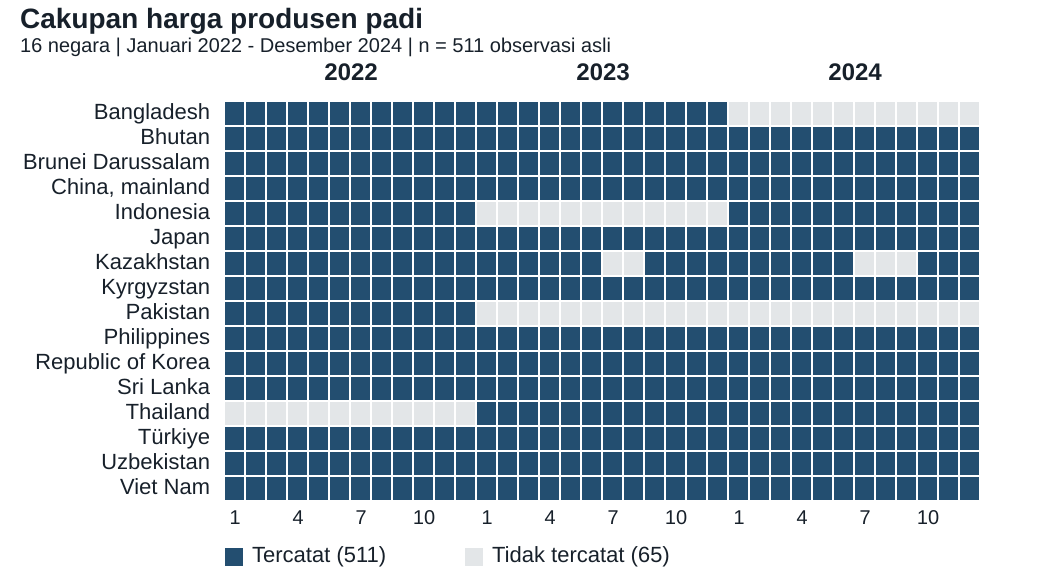

In [5]:
# Heatmap cakupan: kotak abu-abu menyatakan observasi tidak tercatat.
s=svg_start(1040,580,'Cakupan harga produsen padi','16 negara | Januari 2022 - Desember 2024 | n = 511 observasi asli')
left, top, cw, rh = 225, 102, 21, 25
for i,country in enumerate(countries):
    s.append(f'<text x="210" y="{top+i*rh+17}" text-anchor="end" class="label">{html.escape(country)}</text>')
    g=panel[panel.Country.eq(country)]
    for j,v in enumerate(g[PRICE]):
        color='#234e70' if pd.notna(v) else '#e3e6e8'
        s.append(f'<rect x="{left+j*cw}" y="{top+i*rh}" width="19" height="23" fill="{color}"/>')
for year in range(3):
    s.append(f'<text x="{left+year*12*cw+6*cw}" y="80" text-anchor="middle" font-size="24" font-weight="bold">{2022+year}</text>')
    for mo in [0,3,6,9]:
        s.append(f'<text x="{left+(year*12+mo)*cw+10}" y="{top+16*rh+22}" text-anchor="middle" class="small">{mo+1}</text>')
s.extend(['<rect x="225" y="548" width="18" height="18" fill="#234e70"/><text x="252" y="562" class="label">Tercatat (511)</text>',
          '<rect x="465" y="548" width="18" height="18" fill="#e3e6e8"/><text x="492" y="562" class="label">Tidak tercatat (65)</text>'])
show_svg(s)


**Temuan cakupan.** Bangladesh tidak memiliki observasi terpilih pada 2024, Indonesia pada 2023, Pakistan pada 2023–2024, dan Thailand pada 2022. Kazakhstan memiliki lima bulan yang tidak tercatat. Karena itu, sampel didominasi negara dengan seri lebih lengkap dan tidak mewakili seluruh Asia.

Brunei Darussalam memiliki satu nilai harga yang sama sepanjang periode terpilih. Seri ini tetap dipertahankan karena harga tetap merupakan kondisi yang sah menurut definisi target. Penyebabnya tidak diasumsikan sebagai kesalahan pencatatan.

Level LCU tidak digabung untuk membandingkan mahal atau murahnya harga antarnegara. Analisis perubahan dan fitur menggunakan perbandingan relatif pada negara yang sama.

## 10.5 EDA perubahan harga dan nilai ekstrem

Eksplorasi yang dapat memengaruhi rancangan fitur dibatasi pada **jendela latih tahun 2022**. Return satu bulan dihitung sebagai `P(t) / P(t-1) - 1` setelah kalender dilengkapi. `fill_method=None` memastikan harga yang hilang tidak diisi otomatis.

Pagar 1,5 IQR dihitung terpisah pada return setiap negara dalam jendela tersebut. Penandaan ini merupakan pemeriksaan awal, bukan bukti bahwa suatu harga salah. Seluruh nilai tetap dipertahankan.


In [6]:
panel["change_1m"] = panel.groupby("Country", sort=False)[PRICE].transform(
    lambda p: p.pct_change(fill_method=None))
cutoff1, cutoff2 = pd.Timestamp("2023-01-01"), pd.Timestamp("2024-01-01")
returns = panel.loc[(panel.date < cutoff1) & panel.change_1m.notna(),
                    ["Country", "date", "change_1m"]].copy()
returns["iqr_flag"] = False
iqr_rows = []
for country, g in returns.groupby("Country"):
    q1, q3 = g.change_1m.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags = (g.change_1m < low) | (g.change_1m > high)
    returns.loc[g.index, "iqr_flag"] = flags
    iqr_rows.append({"Negara": country, "Return tersedia": len(g),
                     "Batas bawah (%)": low * 100, "Batas atas (%)": high * 100,
                     "Ditandai": int(flags.sum())})
assert len(returns) == 165 and int(returns.iqr_flag.sum()) == 9
display((returns.change_1m * 100).describe().rename("Perubahan bulanan (%)").to_frame().round(4))
display(pd.DataFrame(iqr_rows).round(4))
extremes = returns.reindex(returns.change_1m.abs().sort_values(ascending=False).index).head(5).copy()
extremes["Perubahan (%)"] = extremes.change_1m * 100
display(extremes[["Country", "date", "Perubahan (%)", "iqr_flag"]].round(4))


,Perubahan bulanan (%)
count,165.0000
mean,1.9824
std,7.6669
min,-43.2404
25%,-0.3931
50%,0.4960
75%,3.5656
max,30.6523


,Negara,Return tersedia,Batas bawah (%),Batas atas (%),Ditandai
0,Bangladesh,11,-7.4989,15.7008,1
1,Bhutan,11,-2.2460,3.9068,2
2,Brunei Darussalam,11,0.0000,0.0000,0
3,"China, mainland",11,-2.1944,2.5856,0
4,Indonesia,11,-8.0427,11.3745,0
5,Japan,11,-0.4489,0.6271,2
6,Kazakhstan,11,-40.0029,58.7502,1
7,Kyrgyzstan,11,-10.8186,12.7636,0
8,Pakistan,11,-6.7828,13.7735,1
9,Philippines,11,-6.0025,6.7322,0


,Country,date,Perubahan (%),iqr_flag
222,Kazakhstan,2022-07-01,-43.2404,True
223,Kazakhstan,2022-08-01,30.6523,False
227,Kazakhstan,2022-12-01,27.5552,False
219,Kazakhstan,2022-04-01,24.9613,False
401,Sri Lanka,2022-06-01,24.6305,False


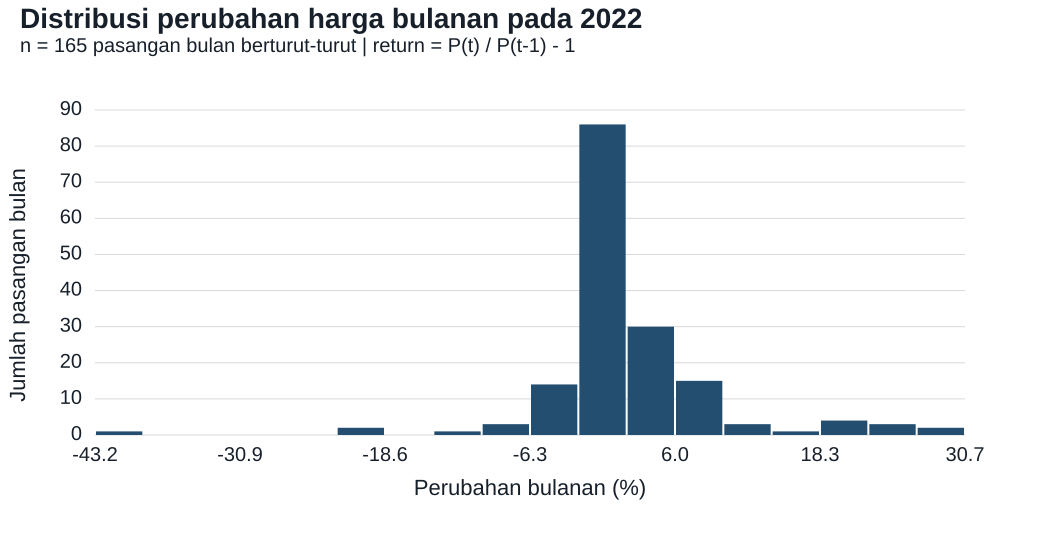

In [7]:
# Histogram perubahan hanya 2022. Semua nilai ditampilkan, tanpa winsorisasi.
counts,bins=np.histogram(returns.change_1m.to_numpy()*100,bins=18)
s=svg_start(1040,550,'Distribusi perubahan harga bulanan pada 2022',f'n = {len(returns)} pasangan bulan berturut-turut | return = P(t) / P(t-1) - 1')
x0,y0,w,h=95,435,870,325
maxc=int(counts.max()); padmax=math.ceil(maxc/10)*10
for tick in range(0,padmax+1,10):
    y=y0-tick/padmax*h
    s.append(f'<line x1="{x0}" y1="{y}" x2="{x0+w}" y2="{y}" stroke="#d9d9d9"/><text x="82" y="{y+5}" text-anchor="end" class="small">{tick}</text>')
for i,n in enumerate(counts):
    bh=n/padmax*h; xx=x0+i*w/len(counts)
    s.append(f'<rect x="{xx+1}" y="{y0-bh}" width="{w/len(counts)-2}" height="{bh}" fill="#234e70"/>')
for tick in np.linspace(bins[0],bins[-1],7):
    x=x0+(tick-bins[0])/(bins[-1]-bins[0])*w
    s.append(f'<text x="{x}" y="{y0+26}" text-anchor="middle" class="small">{tick:.1f}</text>')
s.extend(['<text x="530" y="495" text-anchor="middle" class="label">Perubahan bulanan (%)</text>',
          '<text x="25" y="285" transform="rotate(-90 25 285)" text-anchor="middle" class="label">Jumlah pasangan bulan</text>'])
show_svg(s)


**Temuan distribusi.** Terdapat 165 pasangan bulan berturut-turut dengan return yang valid pada 2022. Median perubahan adalah **0,50%**, kuartil pertama **−0,39%**, dan kuartil ketiga **3,57%**. Rentangnya **−43,24% sampai 30,65%**. Sebagian besar perubahan berada di sekitar nol, tetapi ada beberapa perubahan besar.

Perubahan absolut terbesar terjadi di Kazakhstan pada Juli 2022, kemudian diikuti kenaikan pada Agustus. Sembilan return ditandai oleh pagar IQR per negara. Sampel tiap negara masih terbatas dan belum ada bukti kesalahan dari penerbit, sehingga nilai tersebut tidak dihapus atau diwinsorisasi. Distribusi gabungan ini menggambarkan contoh yang tersedia, bukan tingkat inflasi harga padi seluruh Asia.

## 10.6 Audit fitur, target, dan pembagian waktu

Audit berikut memeriksa apakah informasi yang tersedia cukup untuk membentuk contoh klasifikasi. Fitur hanya memakai harga sampai bulan t pada negara yang sama. Target memakai harga pada **t+1 kalender**, bukan sekadar baris berikutnya yang tersedia.

| Fitur | Definisi | Alasan penggunaan |
|---|---|---|
| `month` | Nomor bulan t, 1–12 | Menandai kalender musim secara sederhana. |
| `change_1m` | P(t) / P(t−1) − 1 | Menggambarkan perubahan satu bulan terakhir. |
| `change_3m` | P(t) / P(t−3) − 1 | Menggambarkan perubahan total tiga bulan. |
| `ratio_to_3m_mean` | P(t) / mean(P(t), P(t−1), P(t−2)) | Menunjukkan posisi harga terhadap rata-rata terbaru. |
| `volatility_3m` | Simpangan baku sampel return t, t−1, t−2, dengan `ddof=1` | Menggambarkan variasi perubahan terbaru. |

Return disimpan sebagai rasio desimal, sehingga 0,05 berarti 5%. Kelima kolom merupakan fitur turunan dari harga dan kalender, bukan lima variabel sumber yang independen. Jika ketentuan pengampu mengharuskan variabel mentah independen, rancangan perlu ditinjau kembali.


In [8]:
feature_parts = []
for country, g in panel.groupby("Country", sort=True):
    q = g.sort_values("date").copy()
    p = q[PRICE]
    q["month"] = q.date.dt.month
    q["change_3m"] = p / p.shift(3) - 1
    q["ratio_to_3m_mean"] = p / p.rolling(3, min_periods=3).mean()
    q["volatility_3m"] = q.change_1m.rolling(3, min_periods=3).std(ddof=1)
    q["target_date"] = q.date + pd.offsets.MonthBegin(1)
    q["next_price"] = p.shift(-1)
    valid = p.notna() & q.next_price.notna()
    q["target"] = pd.Series(pd.NA, index=q.index, dtype="Int64")
    q.loc[valid, "target"] = (q.loc[valid, "next_price"] > p.loc[valid]).astype(int)
    q["direction_actual"] = pd.Series(pd.NA, index=q.index, dtype="Int64")
    q.loc[valid, "direction_actual"] = np.sign(q.loc[valid, "next_price"] - p.loc[valid]).astype(int)
    feature_parts.append(q)
panel = pd.concat(feature_parts, ignore_index=True)
complete = panel.dropna(subset=FEATURES + ["target"]).copy()

# Target yang melewati batas tahun dikeluarkan dari bagian sebelumnya.
train = complete.loc[(complete.date < cutoff1) & (complete.target_date < cutoff1)].copy()
validation = complete.loc[(complete.date >= cutoff1) & (complete.date < cutoff2)
                          & (complete.target_date < cutoff2)].copy()
test = complete.loc[(complete.date >= cutoff2)
                    & (complete.target_date <= pd.Timestamp("2024-12-01"))].copy()
splits = {"Latih": train, "Validasi": validation, "Uji": test}
split_summary = pd.DataFrame([
    {"Bagian": name, "Baris": len(g), "Naik": int(g.target.eq(1).sum()),
     "Tidak naik": int(g.target.eq(0).sum()), "Negara": g.Country.nunique(),
     "Awal fitur": g.date.min().strftime("%Y-%m"), "Akhir fitur": g.date.max().strftime("%Y-%m"),
     "Akhir target": g.target_date.max().strftime("%Y-%m")}
    for name, g in splits.items()])
flow = pd.DataFrame({"Tahap": ["Observasi asli", "Kerangka kalender", "Target tidak tersedia",
                                "Fitur belum lengkap", "Contoh lengkap", "Dikeluarkan pada batas waktu",
                                "Contoh pada protokol utama"],
                     "Jumlah": [len(asia), len(panel), int(panel.target.isna().sum()),
                                int(panel[FEATURES].isna().any(axis=1).sum()), len(complete),
                                len(complete) - sum(map(len, splits.values())), sum(map(len, splits.values()))]})
display(flow)
display(split_summary)
split_coverage = pd.DataFrame({"Negara": countries})
for name, g in splits.items():
    split_coverage[name] = split_coverage.Negara.map(g.Country.value_counts()).fillna(0).astype(int)
display(split_coverage)


,Tahap,Jumlah
0,Observasi asli,511
1,Kerangka kalender,576
2,Target tidak tersedia,84
3,Fitur belum lengkap,122
4,Contoh lengkap,436
5,Dikeluarkan pada batas waktu,26
6,Contoh pada protokol utama,410


,Bagian,Baris,Naik,Tidak naik,Negara,Awal fitur,Akhir fitur,Akhir target
0,Latih,120,78,42,15,2022-04,2022-11,2022-12
1,Validasi,145,91,54,14,2023-01,2023-11,2023-12
2,Uji,145,74,71,14,2024-01,2024-11,2024-12


,Negara,Latih,Validasi,Uji
0,Bangladesh,8,11,0
1,Bhutan,8,11,11
2,Brunei Darussalam,8,11,11
3,"China, mainland",8,11,11
4,Indonesia,8,0,8
5,Japan,8,11,11
6,Kazakhstan,8,5,5
7,Kyrgyzstan,8,11,11
8,Pakistan,8,0,0
9,Philippines,8,11,11


**Kelayakan contoh.** Dari 576 baris kalender, 84 tidak memiliki target dan 122 memiliki set fitur yang belum lengkap. Kedua kelompok ini saling tumpang tindih, sehingga tidak boleh dijumlahkan. Setelah seluruh syarat dipenuhi, tersedia **436 contoh lengkap**. Data ini berupa panel negara-bulan, bukan satu deret 436 bulan.

Sebanyak **26 contoh** dikeluarkan dari protokol utama karena targetnya melewati batas pembagian waktu. Tersisa **410 contoh**, yaitu **120 latih, 145 validasi, dan 145 uji**. Pembagian ini adalah rancangan evaluasi retrospektif satu bulan ke depan yang diperbarui setiap bulan, bukan prediksi seluruh 2024 sekaligus pada awal tahun.

Data latih mencakup 15 negara. Thailand belum muncul pada latih 2022, tetapi hadir pada validasi dan uji. Data uji mencakup 14 negara, tanpa Bangladesh dan Pakistan. Indonesia tidak muncul pada validasi. Komposisi tersebut perlu disertakan ketika hasil model dibahas.

Kelas, fitur, parameter, atau aturan penanganan nilai ekstrem tidak dipilih berdasarkan data uji. Tabel pembagian waktu dipakai untuk memeriksa rancangan dan cakupan, bukan sebagai hasil evaluasi model.


In [9]:
# Korelasi hanya memakai 120 contoh latih. Bulan bukan ukuran linear dalam grafik ini.
corr = train[FEATURES[1:]].corr(method="pearson")
display(corr.round(4))


,change_1m,change_3m,ratio_to_3m_mean,volatility_3m
change_1m,1.0000,0.5521,0.8557,0.1519
change_3m,0.5521,1.0000,0.7618,-0.0076
ratio_to_3m_mean,0.8557,0.7618,1.0000,0.0327
volatility_3m,0.1519,-0.0076,0.0327,1.0000


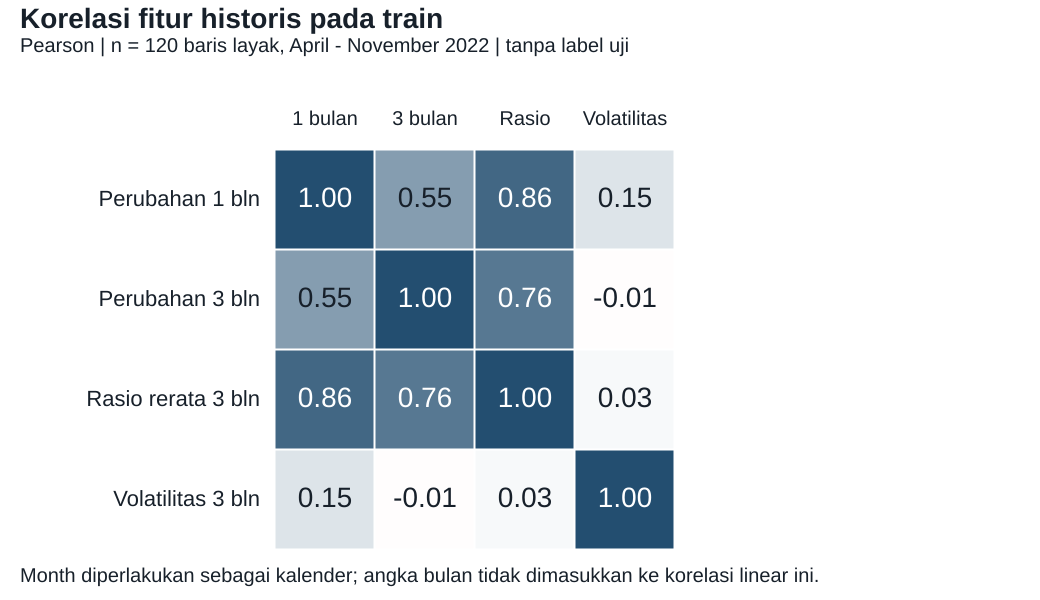

In [10]:
labels=['Perubahan 1 bln','Perubahan 3 bln','Rasio rerata 3 bln','Volatilitas 3 bln']
s=svg_start(1040,600,'Korelasi fitur historis pada train',f'Pearson | n = {len(train)} baris layak, April - November 2022 | tanpa label uji')
left,top,cell=275,150,100
for i,l in enumerate(labels):
    s.append(f'<text x="260" y="{top+i*cell+56}" text-anchor="end" class="label">{l}</text>')
    s.append(f'<text x="{left+i*cell+50}" y="125" text-anchor="middle" class="small">{["1 bulan","3 bulan","Rasio","Volatilitas"][i]}</text>')
    for j in range(4):
        v=float(corr.iloc[i,j]); a=abs(v)
        col=f'rgb({int(255-(220*a))},{int(255-(177*a))},{int(255-(143*a))})' if v>=0 else f'rgb(255,{int(255-150*a)},{int(255-170*a)})'
        s.append(f'<rect x="{left+j*cell}" y="{top+i*cell}" width="99" height="99" fill="{col}" stroke="white"/>')
        s.append(f'<text x="{left+j*cell+50}" y="{top+i*cell+57}" text-anchor="middle" font-size="28" style="fill:{"white" if a>.65 else "#17202a"}">{v:.2f}</text>')
s.append('<text x="20" y="582" class="small">Month diperlakukan sebagai kalender; angka bulan tidak dimasukkan ke korelasi linear ini.</text>')
show_svg(s)


**Temuan korelasi.** Perubahan satu bulan dan rasio terhadap rata-rata tiga bulan berkorelasi sekitar **0,856**. Perubahan tiga bulan dan rasio tersebut berkorelasi sekitar **0,762**. Sebagian fitur memuat informasi yang bertumpang tindih. Ini menjadi bahan pemeriksaan pada tahap pemilihan fitur, bukan bukti hubungan sebab-akibat atau bukti manfaat prediksi.

Nomor bulan tidak dimasukkan ke korelasi linear ini karena merupakan informasi kalender. Keputusan encoding, pengurangan fitur, atau transformasi akan ditetapkan pada tahap persiapan model menggunakan latih dan validasi.


In [11]:
class_counts = pd.DataFrame({"Cakupan": ["Contoh lengkap, sebelum pembagian", "Latih"],
                             "Naik": [int(complete.target.eq(1).sum()), int(train.target.eq(1).sum())],
                             "Tidak naik": [int(complete.target.eq(0).sum()), int(train.target.eq(0).sum())],
                             "Harga tetap di dalam kelas tidak naik": [int(complete.direction_actual.eq(0).sum()),
                                                                      int(train.direction_actual.eq(0).sum())]})
display(class_counts)


,Cakupan,Naik,Tidak naik,Harga tetap di dalam kelas tidak naik
0,"Contoh lengkap, sebelum pembagian",257,179,38
1,Latih,78,42,10


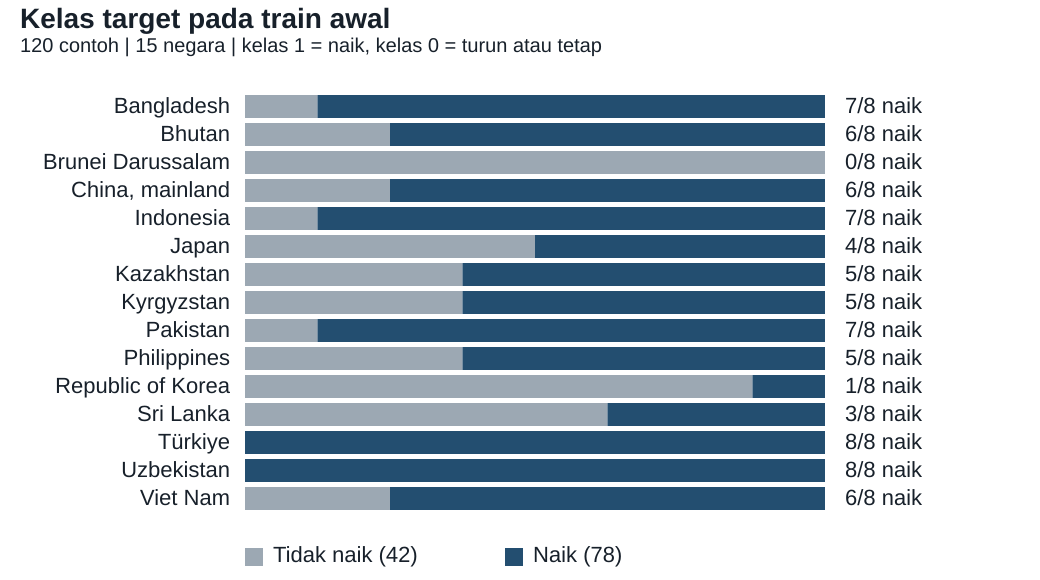

In [12]:
# Ringkasan kelas train per negara, termasuk seri konstan.
s=svg_start(1040,580,'Kelas target pada train awal','120 contoh | 15 negara | kelas 1 = naik, kelas 0 = turun atau tetap')
top,rh,left,width=95,28,245,580
for i,c in enumerate(sorted(train.Country.unique())):
    g=train[train.Country.eq(c)]; n=len(g); up=int(g.target.eq(1).sum()); no=n-up
    s.append(f'<text x="230" y="{top+i*rh+18}" text-anchor="end" class="label">{html.escape(c)}</text>')
    s.append(f'<rect x="{left}" y="{top+i*rh}" width="{width*no/n}" height="23" fill="#9ca8b3"/>')
    s.append(f'<rect x="{left+width*no/n}" y="{top+i*rh}" width="{width*up/n}" height="23" fill="#234e70"/>')
    s.append(f'<text x="845" y="{top+i*rh+18}" class="label">{up}/{n} naik</text>')
s.extend(['<rect x="245" y="548" width="18" height="18" fill="#9ca8b3"/><text x="273" y="562" class="label">Tidak naik (42)</text>',
          '<rect x="505" y="548" width="18" height="18" fill="#234e70"/><text x="533" y="562" class="label">Naik (78)</text>'])
show_svg(s)


**Temuan kelas target.** Pada latih terdapat **78 contoh naik dan 42 tidak naik**, sehingga baseline mayoritas akan memprediksi kelas 1. Komposisi berbeda antarnegara dan Brunei menyumbang contoh harga tetap. Karena itu, accuracy saja belum cukup untuk menilai hasil model.

Audit seluruh 436 contoh lengkap menghasilkan **257 naik dan 179 tidak naik**. Sebanyak **38 contoh harga tetap** termasuk di dalam kelas tidak naik. Ringkasan ini menjelaskan komposisi data. Ambang utama tetap `>0` dan tidak diubah berdasarkan label uji.

## 10.7 Kesimpulan Data Understanding dan tindak lanjut

Data dapat digunakan untuk tahap analisis berikutnya setelah cakupan kalender, satuan, dan batas informasi ditetapkan. Pemeriksaan tidak menemukan duplikasi kunci atau harga tidak positif pada subset. Masalah utama adalah bulan yang tidak tercatat, cakupan negara yang tidak merata, periode pendek, serta tanggal publikasi dan riwayat revisi yang tidak tersedia.

Harga asli dipertahankan. Kolom alternatif yang kosong tidak digunakan, gap kalender tetap ditandai, dan nilai ekstrem tidak dihapus tanpa bukti kesalahan. Audit fitur menghasilkan 436 contoh lengkap dan protokol waktu menyediakan 410 contoh untuk tahap pemodelan.

Berikutnya, kelompok akan menetapkan preprocessing dan feature selection yang diperlukan, memilih model dari materi praktikum, lalu membandingkannya dengan kedua baseline. **Belum ada metrik hasil model.** Manfaat prediktif dan kelayakan penerapan masih perlu diuji.

Sel terakhir memeriksa angka utama dan batas informasi yang mendasari tabel serta grafik dalam laporan. Menjalankan notebook tidak membuat dataset turunan, folder hasil, atau salinan grafik baru di dalam repo. Seluruh keluaran tampil di notebook ini.


In [13]:
assert raw.shape == (5341, 17) and raw.Country.nunique() == 73
assert (len(asia), len(panel), len(complete)) == (511, 576, 436)
assert int(panel[PRICE].isna().sum()) == 65
assert int(panel.target.isna().sum()) == 84
assert int(panel[FEATURES].isna().any(axis=1).sum()) == 122
assert [len(train), len(validation), len(test)] == [120, 145, 145]
assert len(complete) - sum(map(len, splits.values())) == 26
assert int(complete.target.eq(1).sum()) == 257
assert int(complete.target.eq(0).sum()) == 179
assert int(complete.direction_actual.eq(0).sum()) == 38
assert len(returns) == 165 and int(returns.iqr_flag.sum()) == 9
assert (train.date < cutoff1).all() and (train.target_date < cutoff1).all()
assert (validation.date >= cutoff1).all() and (validation.target_date < cutoff2).all()
assert (test.date >= cutoff2).all() and (test.target_date <= pd.Timestamp("2024-12-01")).all()
assert not set(train.index) & set(validation.index)
assert not set(train.index) & set(test.index)
assert not set(validation.index) & set(test.index)
assert (panel.target_date == panel.date + pd.offsets.MonthBegin(1)).all()
assert np.isfinite(complete[FEATURES].to_numpy()).all()
assert panel.loc[panel[PRICE].isna() | panel.next_price.isna(), "target"].isna().all()
print("Audit selesai menggunakan Python " + platform.python_version() + ".")
print("511 observasi asli → 576 baris kalender → 436 contoh lengkap → 410 contoh pada protokol waktu.")
print("Seluruh pemeriksaan lolos. Model belum dilatih.")


Audit selesai menggunakan Python 3.13.12.
511 observasi asli → 576 baris kalender → 436 contoh lengkap → 410 contoh pada protokol waktu.
Seluruh pemeriksaan lolos. Model belum dilatih.
